# Heart Attack Classification - Step by Step
**Target:** `HeartDiseaseorAttack` (0 = No, 1 = Yes)

## Step 1: Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pickle
import warnings
warnings.filterwarnings('ignore')

## Step 2: Load Data

In [5]:
df = pd.read_csv('datasets/Heart_attack.csv')
print('Shape:', df.shape)
df.head()

Shape: (129998, 16)


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,HvyAlcoholConsump,MentHlth,PhysHlth,Sex,Age,Education,Income
0,0,1,1,1,40.0,1,0,0,0,0,18,15,0,9,4,3
1,0,0,0,0,25.0,1,0,0,1,0,0,0,0,7,6,1
2,0,1,1,1,28.0,0,0,0,0,0,30,30,0,9,4,8
3,0,1,0,1,27.0,0,0,0,1,0,0,0,0,11,3,6
4,0,1,1,1,24.0,0,0,0,1,0,3,0,0,11,5,4


## Step 3: Exploratory Data Analysis (EDA)

In [6]:
print(df.info())
print('\nMissing values:\n', df.isnull().sum())
print('\nTarget distribution:\n', df['HeartDiseaseorAttack'].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 129998 entries, 0 to 129997
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   HeartDiseaseorAttack  129998 non-null  int64  
 1   HighBP                129998 non-null  int64  
 2   HighChol              129998 non-null  int64  
 3   CholCheck             129998 non-null  int64  
 4   BMI                   129988 non-null  float64
 5   Smoker                129998 non-null  int64  
 6   Stroke                129998 non-null  int64  
 7   Diabetes              129998 non-null  int64  
 8   PhysActivity          129998 non-null  int64  
 9   HvyAlcoholConsump     129998 non-null  int64  
 10  MentHlth              129998 non-null  int64  
 11  PhysHlth              129998 non-null  int64  
 12  Sex                   129998 non-null  int64  
 13  Age                   129998 non-null  int64  
 14  Education             129998 non-null  int64  
 15  Income     

In [ ]:
df.describe()

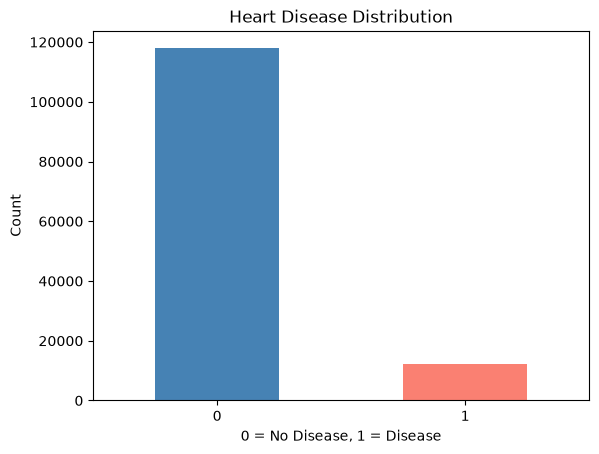

In [7]:
# Target class distribution
df['HeartDiseaseorAttack'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
plt.title('Heart Disease Distribution')
plt.xlabel('0 = No Disease, 1 = Disease')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

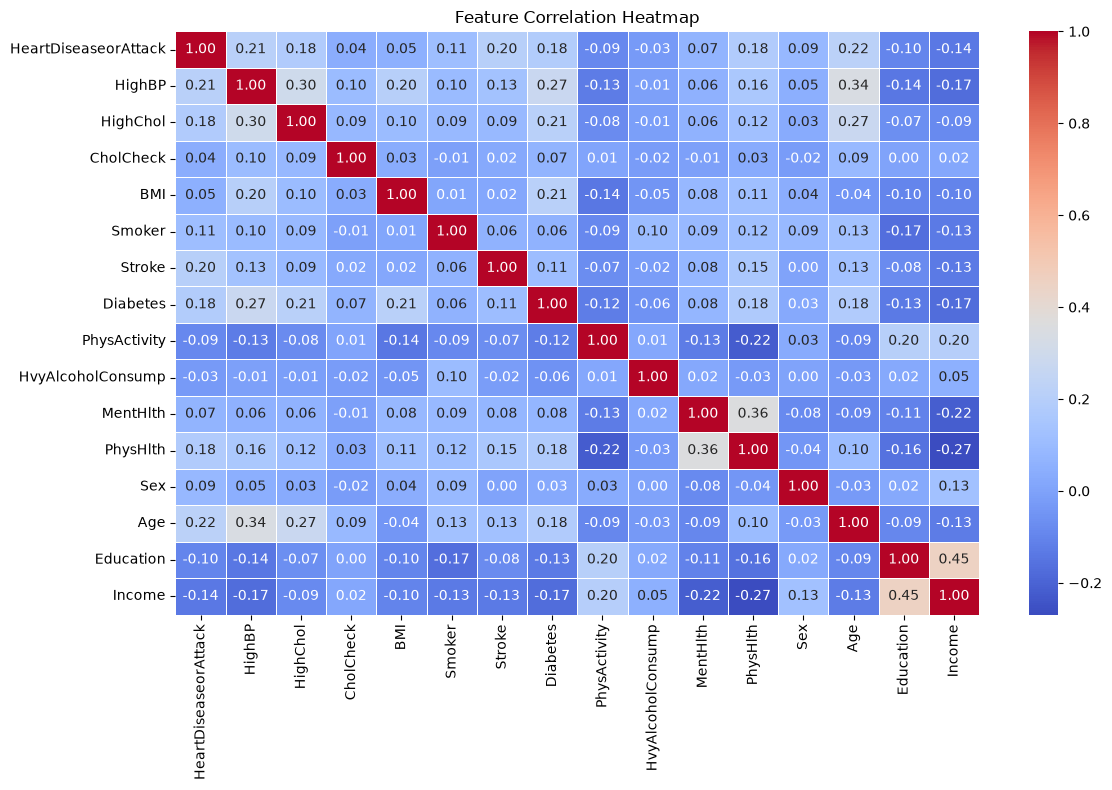

In [8]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## Step 4: Data Preprocessing

In [10]:
# Drop rows with missing values
df_clean = df.dropna()
print('Shape after dropping nulls:', df_clean.shape)

# Separate features and target
X = df_clean.drop('HeartDiseaseorAttack', axis=1)
y = df_clean['HeartDiseaseorAttack']

print('Features shape:', X.shape)
print('Target shape:', y.shape)

Shape after dropping nulls: (129988, 16)
Features shape: (129988, 15)
Target shape: (129988,)


## Step 5: Remove Outliers (IQR Method)

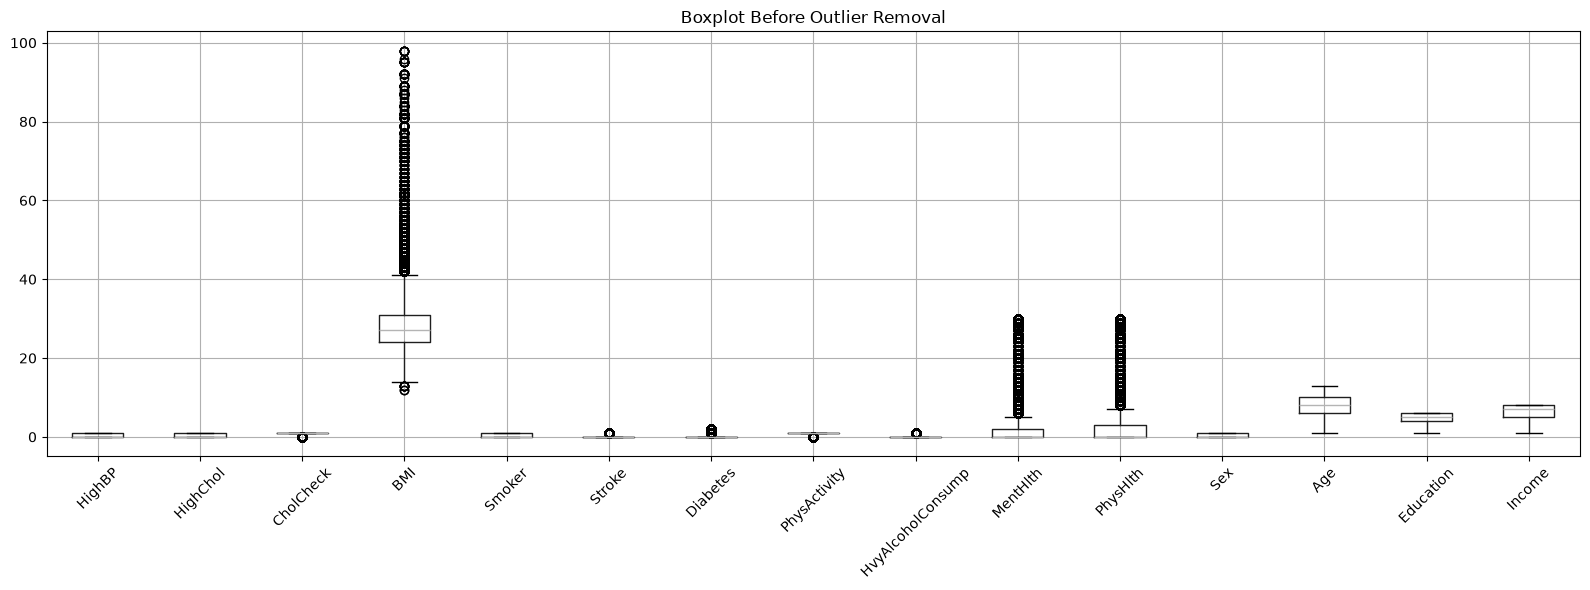

In [12]:
# Visualize outliers before removal
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
plt.figure(figsize=(16, 6))
X[numeric_cols].boxplot()
plt.title('Boxplot Before Outlier Removal')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
# Remove outliers using IQR method on continuous columns
continuous_cols = ['BMI', 'MentHlth', 'PhysHlth', 'Age']

df_no_outliers = pd.concat([X, y], axis=1).copy()
before = len(df_no_outliers)

for col in continuous_cols:
    if col in df_no_outliers.columns:
        Q1 = df_no_outliers[col].quantile(0.25)
        Q3 = df_no_outliers[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_no_outliers = df_no_outliers[(df_no_outliers[col] >= lower) & (df_no_outliers[col] <= upper)]

after = len(df_no_outliers)
print(f'Rows before: {before}')
print(f'Rows after : {after}')
print(f'Outliers removed: {before - after}')

X = df_no_outliers.drop('HeartDiseaseorAttack', axis=1)
y = df_no_outliers['HeartDiseaseorAttack']

Rows before: 129988
Rows after : 93484
Outliers removed: 36504


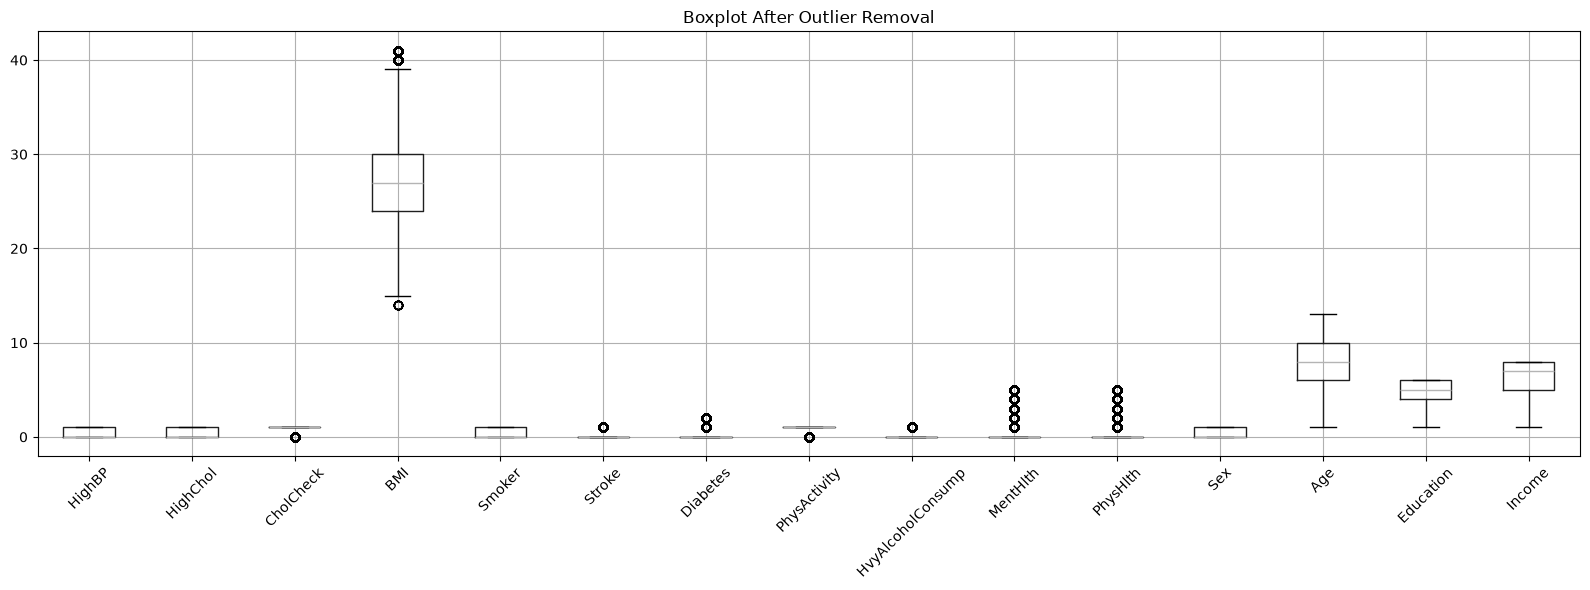

In [14]:
# Visualize after outlier removal
plt.figure(figsize=(16, 6))
X[numeric_cols].boxplot()
plt.title('Boxplot After Outlier Removal')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 6: Train-Test Split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train size:', X_train.shape)
print('Test size:', X_test.shape)

Train size: (74787, 15)
Test size: (18697, 15)


## Step 7: Feature Scaling

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Step 8: Model Training

In [17]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
print('Logistic Regression trained.')

# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
print('Random Forest trained.')

Logistic Regression trained.
Random Forest trained.


## Step 9: Model Evaluation

In [ ]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    print(f'=== {name} ===')
    print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

evaluate_model('Logistic Regression', lr_model, X_test_scaled, y_test)
evaluate_model('Random Forest', rf_model, X_test, y_test)

## Step 10: Feature Importance (Random Forest)

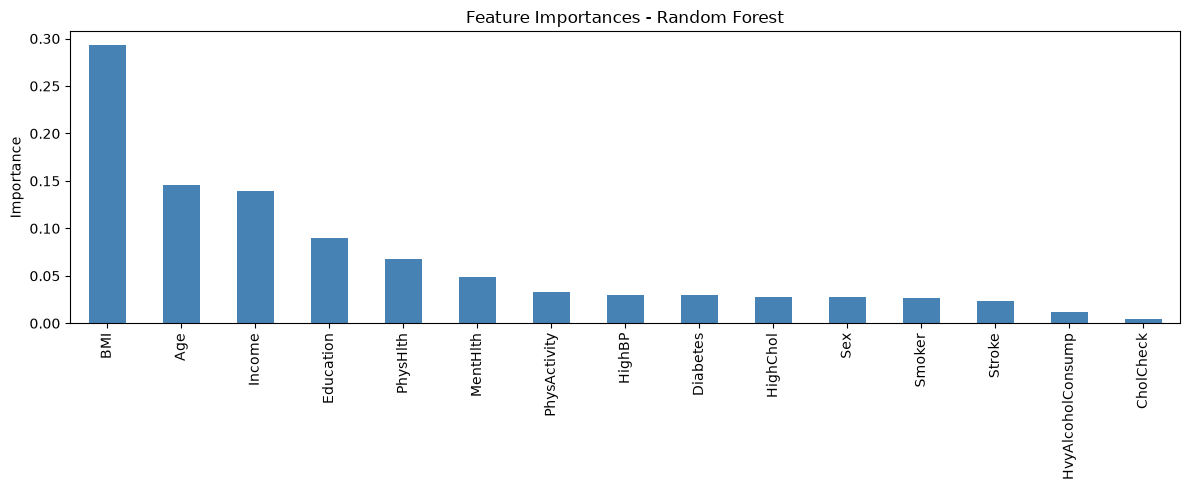

In [18]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.plot(kind='bar', figsize=(12, 5), color='steelblue')
plt.title('Feature Importances - Random Forest')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

## Step 11: Save & Deploy Model

In [19]:
# Save the best model (Random Forest) and scaler
with open('heart_attack_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print('Model and scaler saved successfully!')

Model and scaler saved successfully!


In [20]:
# Load and use the saved model (deployment simulation)
with open('heart_attack_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

# Predict on a new sample (using first test row as example)
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)
probability = loaded_model.predict_proba(sample)

print('Sample input:\n', sample.to_dict(orient='records')[0])
print(f'\nPrediction: {"Heart Disease" if prediction[0] == 1 else "No Heart Disease"}')
print(f'Probability [No Disease, Disease]: {probability[0].round(3)}')

Sample input:
 {'HighBP': 0, 'HighChol': 0, 'CholCheck': 1, 'BMI': 26.0, 'Smoker': 0, 'Stroke': 0, 'Diabetes': 0, 'PhysActivity': 1, 'HvyAlcoholConsump': 0, 'MentHlth': 0, 'PhysHlth': 0, 'Sex': 1, 'Age': 12, 'Education': 6, 'Income': 8}

Prediction: No Heart Disease
Probability [No Disease, Disease]: [0.848 0.152]
